# Q2 · Part B (images) — Random Forest experiments on **Intel Image Classification**

> **Before running:** download the Kaggle dataset *Intel Image Classification* and unzip it into `data/q2_intel/`
> (it should contain `seg_train/seg_train/<class>/*.jpg` and `seg_test/seg_test/<class>/*.jpg`; `seg_pred` is not used).

The dataset has 6 classes (buildings, forest, glacier, mountain, sea, street), ~14k training and 3k test images.
We use the **official train/test split** of the dataset (this is the standard split), shrink the images and flatten them into feature vectors.

⏱ Expected run time: roughly 10–25 minutes (the tree-count sweep is the slow part). To make a quick test run set `MAX_PER_CLASS = 300` and `SWEEP_SEEDS = [0]`.

In [1]:
# ---- Project setup: finds the project root automatically ----
import os, sys, json, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

def find_root():
    start = Path(os.environ.get("LAB_ROOT", Path.cwd())).resolve()
    for p in [start, *start.parents]:
        if (p / "requirements.txt").exists() and (p / "src").exists():
            return p
    raise RuntimeError("Project root not found. Open this notebook from inside the Prog_for_AI_Lab folder.")

ROOT = find_root()
sys.path.insert(0, str(ROOT / "src"))
print("Project root:", ROOT)

Project root: C:\Users\hp\Desktop\Prog_for_AI_Lab\Prog_for_AI_Lab


In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, classification_report
from lab_utils import *
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

In [3]:
IMG_SIZE       = 32          # images are resized to IMG_SIZE x IMG_SIZE (150x150 originals are too large for tree models)
MAX_PER_CLASS  = None        # None = use all images; e.g. 300 for a fast test run
FEATURE_MODE   = "pixels"    # "pixels" (raw RGB) or "hog_color" (HOG edges + colour histograms)
SEED           = 42
N_LIST         = [1, 10, 50, 100, 300]
SWEEP_SEEDS    = [0, 1, 2]
PCA_COMPONENTS = 100         # used only for the SVM (RBF-SVM on 3072 raw features is very slow)

## 1. Load images

Loading training images ...
Loading test images ...
Loaded in 127.9s | train (14034, 32, 32, 3), test (3000, 32, 32, 3) | classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


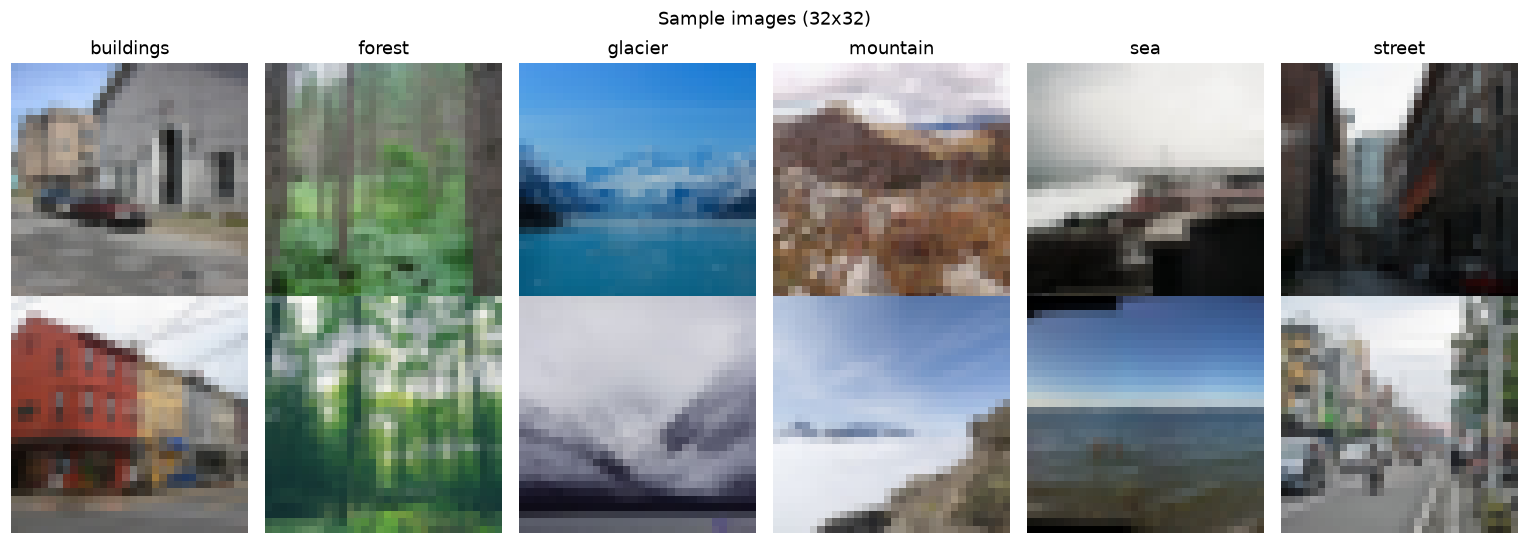

,train,test
buildings,2191,437
forest,2271,474
glacier,2404,553
mountain,2512,525
sea,2274,510
street,2382,501


In [4]:
t = time.perf_counter()
Itr, ytr, Ite, yte, classes = load_intel_images(ROOT / "data" / "q2_intel", IMG_SIZE, MAX_PER_CLASS, SEED)
print(f"Loaded in {time.perf_counter()-t:.1f}s | train {Itr.shape}, test {Ite.shape} | classes: {classes}")
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
rng = np.random.default_rng(0)
for ci, c in enumerate(classes):
    idx = rng.choice(np.where(ytr == ci)[0], 2, replace=False)
    for r, i in enumerate(idx):
        axes[r, ci].imshow(Itr[i]); axes[r, ci].axis("off"); axes[r, ci].set_title(c if r == 0 else "")
plt.suptitle(f"Sample images ({IMG_SIZE}x{IMG_SIZE})"); plt.tight_layout(); savefig(fig, "q2", "intel_samples"); plt.show()
counts = pd.DataFrame({"train": np.bincount(ytr), "test": np.bincount(yte)}, index=classes); display(counts)

## 2. Preprocessing
Pixels are scaled to [0, 1] and flattened. Trees do not need further scaling; the SVM pipeline adds standardisation + PCA.

In [5]:
Xtr = image_features(Itr, FEATURE_MODE); Xte = image_features(Ite, FEATURE_MODE)
print("feature matrix:", Xtr.shape, Xtr.dtype)

feature matrix: (14034, 3072) float32


## 3. Experiment 1 — test accuracy vs number of trees

  n_estimators=   1 done
  n_estimators=  10 done
  n_estimators=  50 done
  n_estimators= 100 done
  n_estimators= 300 done


,n_estimators,test_acc_mean,test_acc_std,train_acc_mean,oob_acc_mean,train_time_mean
0,1,0.4036,0.0093,0.7820,NaN,0.7696
1,10,0.5284,0.0050,0.9896,0.4574,3.3404
2,50,0.5913,0.0050,0.9992,0.5673,16.7550
3,100,0.6064,0.0032,0.9993,0.5910,34.2463
4,300,0.6144,0.0038,0.9993,0.6137,100.5707


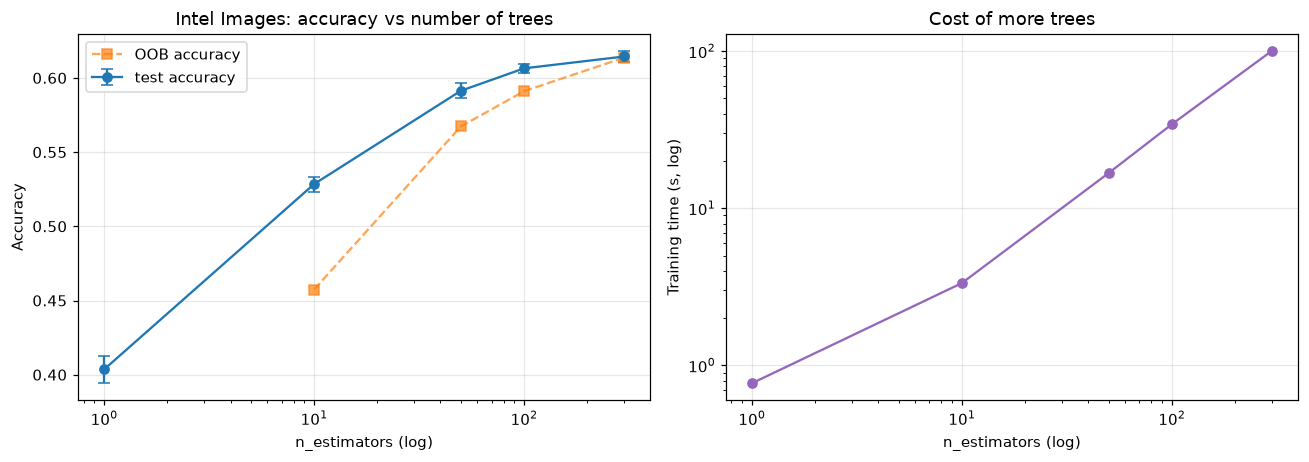

In [6]:
sweep = sweep_n_estimators(Xtr, ytr, Xte, yte, ns=N_LIST, seeds=SWEEP_SEEDS)
summary = summarize_sweep(sweep); display(summary.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].errorbar(summary.n_estimators, summary.test_acc_mean, yerr=summary.test_acc_std, fmt="o-", capsize=4, label="test accuracy")
axes[0].plot(summary.n_estimators, summary.oob_acc_mean, "s--", alpha=0.7, label="OOB accuracy")
axes[0].set_xscale("log"); axes[0].set_xlabel("n_estimators (log)"); axes[0].set_ylabel("Accuracy"); axes[0].legend(); axes[0].set_title("Intel Images: accuracy vs number of trees")
axes[1].plot(summary.n_estimators, summary.train_time_mean, "o-", color="tab:purple"); axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("n_estimators (log)"); axes[1].set_ylabel("Training time (s, log)"); axes[1].set_title("Cost of more trees")
plt.tight_layout(); savefig(fig, "q2", "intel_n_estimators"); plt.show()

## 4. Experiment 2 — single Decision Tree vs Random Forest (default parameters)

In [7]:
avg = "macro"
dt_res, dt_model, dt_pred = evaluate_model(DecisionTreeClassifier(random_state=SEED), Xtr, ytr, Xte, yte, "Decision Tree (default)", n_repeats=2, average=avg)
rf_res, rf_model, rf_pred = evaluate_model(RandomForestClassifier(random_state=SEED, n_jobs=-1), Xtr, ytr, Xte, yte, "Random Forest (default, 100 trees)", n_repeats=1, average=avg)
dt_vs_rf = [dt_res, rf_res]; display(pd.DataFrame(dt_vs_rf).round(4))

,model,accuracy,precision,recall,f1,train_time_s,predict_time_s,roc_auc
0,Decision Tree (default),0.4460,0.4460,0.4464,0.4459,152.5700,0.0260,0.6679
1,"Random Forest (default, 100 trees)",0.6007,0.5948,0.5984,0.5924,79.3932,0.2535,0.8784


## 5. Experiment 3 — comparison with SVM and Decision Tree
The SVM uses `StandardScaler → PCA → SVC(RBF)`. PCA keeps the training time reasonable (and is a fair preprocessing step for an SVM on pixels).

In [8]:
svm_pipe = Pipeline([("scale", StandardScaler()), ("pca", PCA(PCA_COMPONENTS, random_state=SEED)), ("svm", SVC(random_state=SEED))])
svm_res, svm_model, svm_pred = evaluate_model(svm_pipe, Xtr, ytr, Xte, yte, f"SVM (RBF + PCA-{PCA_COMPONENTS})", n_repeats=1, average=avg)
comparison = [dt_res, rf_res, svm_res]
display(pd.DataFrame(comparison).round(4))

,model,accuracy,precision,recall,f1,train_time_s,predict_time_s,roc_auc
0,Decision Tree (default),0.4460,0.4460,0.4464,0.4459,152.5700,0.0260,0.6679
1,"Random Forest (default, 100 trees)",0.6007,0.5948,0.5984,0.5924,79.3932,0.2535,0.8784
2,SVM (RBF + PCA-100),0.6477,0.6457,0.6463,0.6425,41.5430,13.5136,NaN


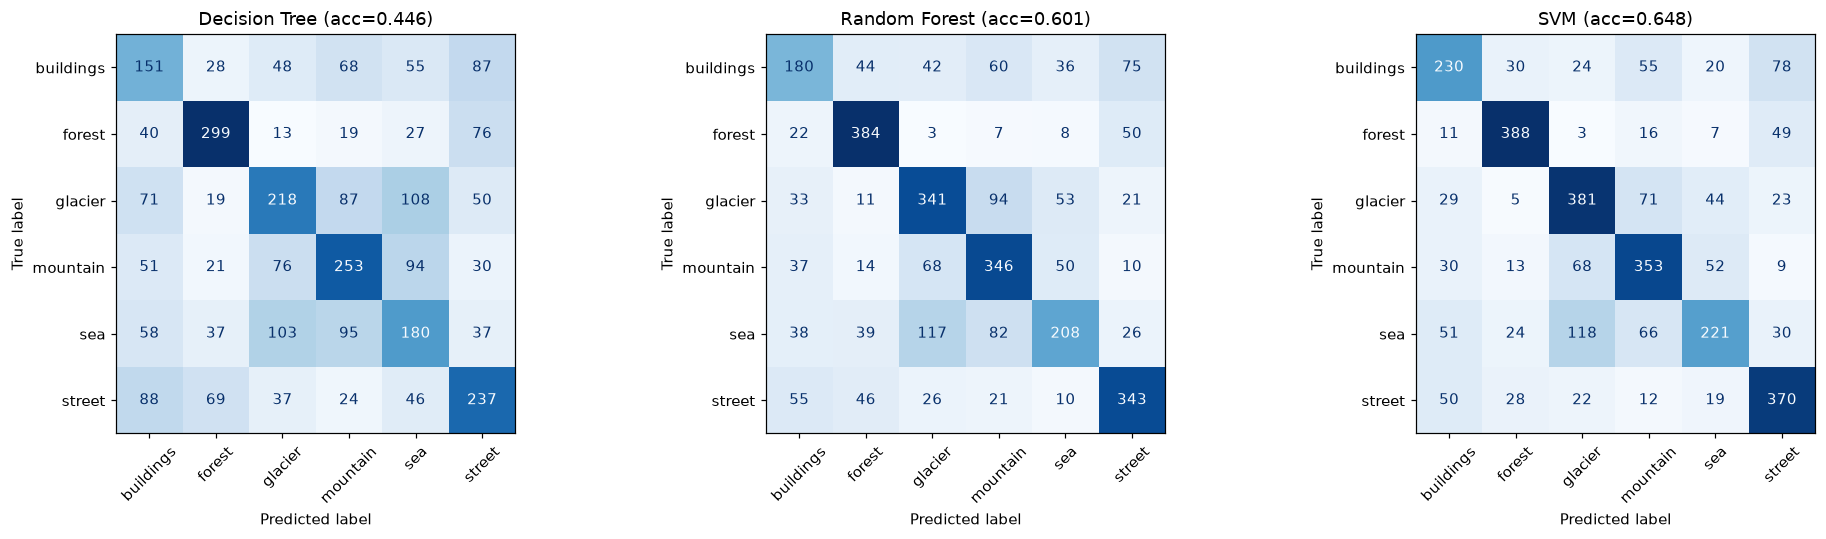

              precision    recall  f1-score   support

   buildings       0.49      0.41      0.45       437
      forest       0.71      0.81      0.76       474
     glacier       0.57      0.62      0.59       553
    mountain       0.57      0.66      0.61       525
         sea       0.57      0.41      0.48       510
      street       0.65      0.68      0.67       501

    accuracy                           0.60      3000
   macro avg       0.59      0.60      0.59      3000
weighted avg       0.60      0.60      0.59      3000



In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, pred) in zip(axes, [("Decision Tree", dt_pred), ("Random Forest", rf_pred), ("SVM", svm_pred)]):
    ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=classes).plot(ax=ax, colorbar=False, cmap="Blues", xticks_rotation=45)
    ax.set_title(f"{name} (acc={np.mean(pred == yte):.3f})"); ax.grid(False)
plt.tight_layout(); savefig(fig, "q2", "intel_confusion"); plt.show()
print(classification_report(yte, rf_pred, target_names=classes))

## 6. Save results

In [ ]:
report = classification_report(yte, rf_pred, target_names=classes, output_dict=True)
results = {
  "dataset": {"name": "Intel Image Classification", "classes": classes, "n_train": int(len(ytr)), "n_test": int(len(yte)),
              "image_size": IMG_SIZE, "feature_mode": FEATURE_MODE, "n_features": int(Xtr.shape[1]), "pca_components_svm": PCA_COMPONENTS,
              "max_per_class": MAX_PER_CLASS, "train_per_class": np.bincount(ytr).tolist(), "test_per_class": np.bincount(yte).tolist()},
  "preprocessing": f"Official train/test split; images resized to {IMG_SIZE}x{IMG_SIZE} RGB, scaled to [0,1], flattened ({Xtr.shape[1]} features). SVM: StandardScaler + PCA({PCA_COMPONENTS}).",
  "sweep_raw": sweep.to_dict("records"), "sweep_summary": summary.to_dict("records"),
  "dt_vs_rf": dt_vs_rf, "comparison": comparison, "rf_per_class": {c: report[c] for c in classes},
  "seeds": SWEEP_SEEDS, "n_list": N_LIST,
}
save_json(results, ROOT / "results" / "q2" / "intel_results.json")
print("Saved results/q2/intel_results.json ✔")

Saved results/q2/intel_results.json ✔


: 